In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

DATA_PATH = "../outputs/cleaned_data/"
OUTPUT_PATH = "../outputs/pressure_analysis/"

import os
os.makedirs(OUTPUT_PATH, exist_ok=True)

# Load cleaned IPL datasets
matches = pd.read_csv(DATA_PATH + "matches_cleaned.csv")
ball_by_ball = pd.read_csv(DATA_PATH + "ball_by_ball_cleaned.csv")

matches["match_date"] = pd.to_datetime(matches["match_date"])

print("Matches shape:", matches.shape)
print("Ball-by-ball shape:", ball_by_ball.shape)

Matches shape: (883, 22)
Ball-by-ball shape: (200999, 33)


In [13]:
# Identify IPL matches

ipl_matches = matches[
    matches["comp_name"].str.fullmatch(
        r"IPL \d{4}",
        na=False
    )
].copy()

# Filter ball-by-ball records for IPL matches
ipl_deliveries = ball_by_ball[
    ball_by_ball["match_id"].isin(ipl_matches["match_id"])
].copy()

# Keep regular innings only (innings 1 and 2)
ipl_regular_deliveries = ipl_deliveries[
    ipl_deliveries["innings"].isin([1, 2])
].copy()

print("IPL matches:", len(ipl_matches))
print("Total IPL deliveries:", len(ipl_deliveries))
print("Regular IPL deliveries:", len(ipl_regular_deliveries))
print("\nInnings distribution:")
print(ipl_regular_deliveries["innings"].value_counts().sort_index())

IPL matches: 371
Total IPL deliveries: 87687
Regular IPL deliveries: 87673

Innings distribution:
innings
1    45588
2    42085
Name: count, dtype: int64


In [3]:
print("Matches columns:")
print(matches.columns.tolist())

print("\nBall-by-ball columns:")
print(ball_by_ball.columns.tolist())

Matches columns:
['match_id', 'comp_id', 'match_number', 'match_date', 'stage', 'venue_id', 'venue_country', 'home_team_id', 'home_team', 'away_team_id', 'away_team', 'home_team_captain_id', 'away_team_captain_id', 'toss_win_team_id', 'toss_opted', 'man_of_the_match', 'first_inn_revised_overs', 'second_inn_revised_overs', 'revised_target', 'knock_out', 'win_team_id', 'result']

Ball-by-ball columns:
['match_id', 'innings', 'overid', 'over_ball_num', 'innings_ball_num', 'batting_team_id', 'bowling_team_id', 'striker_id', 'striker_name', 'non_striker_id', 'non_striker_name', 'bowler_id', 'bowler_name', 'batting_type', 'bowling_type', 'batting_order', 'runs', 'is_four', 'is_six', 'is_wicket', 'dismissal_type_id', 'dismissal_type', 'dismissed_player_id', 'extras_type', 'extras1_runs', 'extras_2_runs', 'pace_or_spin', 'bowl_speed', 'stroke', 'delivery_style', 'over_or_around', 'on_or_off', 'delivery_ist_time']


In [12]:
print("Competition columns:")
print(competitions.columns.tolist())

print("\nCompetition sample:")
display(competitions.head())

print("\nMatches columns after merge:")
print(matches.columns.tolist())

Competition columns:
['comp_id', 'comp_name', 'match_format', 'season']

Competition sample:


,comp_id,comp_name,match_format,season
0,3395,South Africa in New Zealand T20I Series 2026,T20I,2026
1,3405,Afghanistan v Sri Lanka T20I Series 2026,T20I,2026
2,3465,India in Zimbabwe T20I Series 2026,T20I,2026
3,3568,Bangladesh in Zimbabwe T20I Series 2026,T20I,2026
4,3482,Australia in Bangladesh T20I Series 2026,T20I,2026



Matches columns after merge:
['match_id', 'comp_id', 'match_number', 'match_date', 'stage', 'venue_id', 'venue_country', 'home_team_id', 'home_team', 'away_team_id', 'away_team', 'home_team_captain_id', 'away_team_captain_id', 'toss_win_team_id', 'toss_opted', 'man_of_the_match', 'first_inn_revised_overs', 'second_inn_revised_overs', 'revised_target', 'knock_out', 'win_team_id', 'result', 'comp_name']


In [6]:
# Load competition dataset

competitions = pd.read_csv(
    DATA_PATH + "competitions_cleaned.csv"
)

print("Competition shape:", competitions.shape)
print("Competition columns:")
print(competitions.columns.tolist())

display(competitions.head())

Competition shape: (141, 4)
Competition columns:
['comp_id', 'comp_name', 'match_format', 'season']


,comp_id,comp_name,match_format,season
0,3395,South Africa in New Zealand T20I Series 2026,T20I,2026
1,3405,Afghanistan v Sri Lanka T20I Series 2026,T20I,2026
2,3465,India in Zimbabwe T20I Series 2026,T20I,2026
3,3568,Bangladesh in Zimbabwe T20I Series 2026,T20I,2026
4,3482,Australia in Bangladesh T20I Series 2026,T20I,2026


In [7]:
# Merge competition names into matches

matches = matches.merge(
    competitions[["comp_id", "comp_name"]],
    on="comp_id",
    how="left",
    validate="many_to_one"
)

# Identify IPL matches
ipl_matches = matches[
    matches["comp_name"].str.fullmatch(
        r"IPL \d{4}",
        na=False
    )
].copy()

# Filter IPL deliveries
ipl_deliveries = ball_by_ball[
    ball_by_ball["match_id"].isin(ipl_matches["match_id"])
].copy()

# Keep regular innings only
ipl_regular_deliveries = ipl_deliveries[
    ipl_deliveries["innings"].isin([1, 2])
].copy()

print("IPL matches:", len(ipl_matches))
print("Total IPL deliveries:", len(ipl_deliveries))
print("Regular IPL deliveries:", len(ipl_regular_deliveries))

print("\nInnings distribution:")
print(ipl_regular_deliveries["innings"].value_counts().sort_index())

IPL matches: 371
Total IPL deliveries: 87687
Regular IPL deliveries: 87673

Innings distribution:
innings
1    45588
2    42085
Name: count, dtype: int64


In [8]:
# Calculate total runs scored on each delivery

ipl_regular_deliveries["total_runs"] = (
    ipl_regular_deliveries["runs"].fillna(0)
    + ipl_regular_deliveries["extras1_runs"].fillna(0)
    + ipl_regular_deliveries["extras_2_runs"].fillna(0)
)

# Identify legal deliveries
ipl_regular_deliveries["is_legal_ball"] = (
    ~ipl_regular_deliveries["extras_type"].isin(["wide", "Overstep"])
)

# Verify calculations
print("Total delivery records:", len(ipl_regular_deliveries))

print(
    "Total runs:",
    ipl_regular_deliveries["total_runs"].sum()
)

print(
    "Legal balls:",
    ipl_regular_deliveries["is_legal_ball"].sum()
)

print("\nLegal and illegal delivery counts:")
print(ipl_regular_deliveries["is_legal_ball"].value_counts())

Total delivery records: 87673
Total runs: 130003
Legal balls: 83864

Legal and illegal delivery counts:
is_legal_ball
True     83864
False     3809
Name: count, dtype: int64


In [9]:
# Sort deliveries in match order

ipl_regular_deliveries = ipl_regular_deliveries.sort_values(
    ["match_id", "innings", "overid", "over_ball_num"]
).copy()

# Calculate cumulative runs within each innings
ipl_regular_deliveries["cumulative_runs"] = (
    ipl_regular_deliveries
    .groupby(["match_id", "innings"])["total_runs"]
    .cumsum()
)

# Calculate cumulative legal balls
ipl_regular_deliveries["cumulative_legal_balls"] = (
    ipl_regular_deliveries
    .groupby(["match_id", "innings"])["is_legal_ball"]
    .cumsum()
)

display(
    ipl_regular_deliveries[
        [
            "match_id",
            "innings",
            "overid",
            "over_ball_num",
            "total_runs",
            "cumulative_runs",
            "is_legal_ball",
            "cumulative_legal_balls"
        ]
    ].head(15)
)

,match_id,innings,overid,over_ball_num,total_runs,cumulative_runs,is_legal_ball,cumulative_legal_balls
3191,14094,1,1,1,1,1,False,0
3192,14094,1,1,2,0,1,True,1
3193,14094,1,1,3,1,2,False,1
3194,14094,1,1,4,0,2,True,2
3195,14094,1,1,5,0,2,True,3
3196,14094,1,1,6,1,3,False,3
3197,14094,1,1,7,0,3,True,4
3198,14094,1,1,8,0,3,True,5
3199,14094,1,1,9,0,3,True,6
3200,14094,1,2,1,0,3,True,7


In [10]:
# Identify wicket deliveries
ipl_regular_deliveries["wicket_flag"] = (
    ipl_regular_deliveries["is_wicket"].fillna(False).astype(int)
)

# Calculate cumulative wickets lost in each innings
ipl_regular_deliveries["cumulative_wickets"] = (
    ipl_regular_deliveries
    .groupby(["match_id", "innings"])["wicket_flag"]
    .cumsum()
)

# Calculate wickets remaining
ipl_regular_deliveries["wickets_remaining"] = (
    10 - ipl_regular_deliveries["cumulative_wickets"]
)

# Display sample
display(
    ipl_regular_deliveries[
        [
            "match_id",
            "innings",
            "overid",
            "over_ball_num",
            "is_wicket",
            "cumulative_wickets",
            "wickets_remaining"
        ]
    ].head(20)
)

,match_id,innings,overid,over_ball_num,is_wicket,cumulative_wickets,wickets_remaining
3191,14094,1,1,1,False,0,10
3192,14094,1,1,2,False,0,10
3193,14094,1,1,3,False,0,10
3194,14094,1,1,4,False,0,10
3195,14094,1,1,5,True,1,9
3196,14094,1,1,6,False,1,9
3197,14094,1,1,7,False,1,9
3198,14094,1,1,8,False,1,9
3199,14094,1,1,9,False,1,9
3200,14094,1,2,1,False,1,9


In [11]:
# Validate cumulative wicket calculations

print(
    "Maximum cumulative wickets:",
    ipl_regular_deliveries["cumulative_wickets"].max()
)

print(
    "Minimum wickets remaining:",
    ipl_regular_deliveries["wickets_remaining"].min()
)

print(
    "Deliveries with a wicket:",
    ipl_regular_deliveries["wicket_flag"].sum()
)

print(
    "Rows with negative wickets remaining:",
    (ipl_regular_deliveries["wickets_remaining"] < 0).sum()
)

Maximum cumulative wickets: 10
Minimum wickets remaining: 0
Deliveries with a wicket: 4454
Rows with negative wickets remaining: 0


In [17]:
# Calculate current run rate

ipl_regular_deliveries["current_run_rate"] = np.where(
    ipl_regular_deliveries["cumulative_legal_balls"] > 0,
    (
        ipl_regular_deliveries["cumulative_runs"]
        / ipl_regular_deliveries["cumulative_legal_balls"]
    ) * 6,
    np.nan
)

display(
    ipl_regular_deliveries[
        [
            "match_id",
            "innings",
            "overid",
            "over_ball_num",
            "cumulative_runs",
            "cumulative_legal_balls",
            "current_run_rate"
        ]
    ].head(15)
)

,match_id,innings,overid,over_ball_num,cumulative_runs,cumulative_legal_balls,current_run_rate
3191,14094,1,1,1,1,0,NaN
3192,14094,1,1,2,1,1,6.000000
3193,14094,1,1,3,2,1,12.000000
3194,14094,1,1,4,2,2,6.000000
3195,14094,1,1,5,2,3,4.000000
3196,14094,1,1,6,3,3,6.000000
3197,14094,1,1,7,3,4,4.500000
3198,14094,1,1,8,3,5,3.600000
3199,14094,1,1,9,3,6,3.000000
3200,14094,1,2,1,3,7,2.571429


In [15]:
print("Current columns:")
print(ipl_regular_deliveries.columns.tolist())

print("\nCumulative legal balls exists:",
      "cumulative_legal_balls" in ipl_regular_deliveries.columns)

print("Cumulative runs exists:",
      "cumulative_runs" in ipl_regular_deliveries.columns)

Current columns:
['match_id', 'innings', 'overid', 'over_ball_num', 'innings_ball_num', 'batting_team_id', 'bowling_team_id', 'striker_id', 'striker_name', 'non_striker_id', 'non_striker_name', 'bowler_id', 'bowler_name', 'batting_type', 'bowling_type', 'batting_order', 'runs', 'is_four', 'is_six', 'is_wicket', 'dismissal_type_id', 'dismissal_type', 'dismissed_player_id', 'extras_type', 'extras1_runs', 'extras_2_runs', 'pace_or_spin', 'bowl_speed', 'stroke', 'delivery_style', 'over_or_around', 'on_or_off', 'delivery_ist_time']

Cumulative legal balls exists: False
Cumulative runs exists: False


In [16]:
# Sort deliveries chronologically within each innings
ipl_regular_deliveries = ipl_regular_deliveries.sort_values(
    ["match_id", "innings", "overid", "over_ball_num"]
).copy()

# Total runs per delivery
ipl_regular_deliveries["total_runs"] = (
    ipl_regular_deliveries["runs"].fillna(0)
    + ipl_regular_deliveries["extras1_runs"].fillna(0)
    + ipl_regular_deliveries["extras_2_runs"].fillna(0)
)

# Legal delivery indicator
ipl_regular_deliveries["is_legal_ball"] = (
    ~ipl_regular_deliveries["extras_type"].isin(["wide", "Overstep"])
)

# Cumulative runs
ipl_regular_deliveries["cumulative_runs"] = (
    ipl_regular_deliveries
    .groupby(["match_id", "innings"])["total_runs"]
    .cumsum()
)

# Cumulative legal balls
ipl_regular_deliveries["cumulative_legal_balls"] = (
    ipl_regular_deliveries
    .groupby(["match_id", "innings"])["is_legal_ball"]
    .cumsum()
)

# Cumulative wickets
ipl_regular_deliveries["wicket_flag"] = (
    ipl_regular_deliveries["is_wicket"].fillna(False).astype(int)
)

ipl_regular_deliveries["cumulative_wickets"] = (
    ipl_regular_deliveries
    .groupby(["match_id", "innings"])["wicket_flag"]
    .cumsum()
)

# Wickets remaining
ipl_regular_deliveries["wickets_remaining"] = (
    10 - ipl_regular_deliveries["cumulative_wickets"]
)

print("Cumulative calculations restored.")
print("Rows:", len(ipl_regular_deliveries))
print(
    ipl_regular_deliveries[
        [
            "total_runs",
            "cumulative_runs",
            "cumulative_legal_balls",
            "cumulative_wickets",
            "wickets_remaining"
        ]
    ].head(10)
)

Cumulative calculations restored.
Rows: 87673
      total_runs  cumulative_runs  cumulative_legal_balls  cumulative_wickets  \
3191           1                1                       0                   0   
3192           0                1                       1                   0   
3193           1                2                       1                   0   
3194           0                2                       2                   0   
3195           0                2                       3                   1   
3196           1                3                       3                   1   
3197           0                3                       4                   1   
3198           0                3                       5                   1   
3199           0                3                       6                   1   
3200           0                3                       7                   1   

      wickets_remaining  
3191                 10  
3192      

In [18]:
ipl_regular_deliveries["current_run_rate"] = np.where(
    ipl_regular_deliveries["cumulative_legal_balls"] > 0,
    (
        ipl_regular_deliveries["cumulative_runs"]
        / ipl_regular_deliveries["cumulative_legal_balls"]
    ) * 6,
    np.nan
)

display(
    ipl_regular_deliveries[
        [
            "match_id",
            "innings",
            "cumulative_runs",
            "cumulative_legal_balls",
            "current_run_rate"
        ]
    ].head(15)
)

print("\nCurrent run rate summary:")
print(ipl_regular_deliveries["current_run_rate"].describe())

,match_id,innings,cumulative_runs,cumulative_legal_balls,current_run_rate
3191,14094,1,1,0,NaN
3192,14094,1,1,1,6.000000
3193,14094,1,2,1,12.000000
3194,14094,1,2,2,6.000000
3195,14094,1,2,3,4.000000
3196,14094,1,3,3,6.000000
3197,14094,1,3,4,4.500000
3198,14094,1,3,5,3.600000
3199,14094,1,3,6,3.000000
3200,14094,1,3,7,2.571429



Current run rate summary:
count    87627.000000
mean         8.741723
std          2.707947
min          0.000000
25%          7.263158
50%          8.715789
75%         10.105263
max         54.000000
Name: current_run_rate, dtype: float64


In [19]:
innings_scores = (
    ipl_regular_deliveries
    .groupby(["match_id", "innings"], as_index=False)
    .agg(
        innings_total=("total_runs", "sum"),
        legal_balls=("is_legal_ball", "sum")
    )
)

display(innings_scores.head(10))

print("Total innings records:", len(innings_scores))
print("Innings distribution:")
print(innings_scores["innings"].value_counts().sort_index())

,match_id,innings,innings_total,legal_balls
0,14094,1,131,121
1,14094,2,133,111
2,14095,1,177,120
3,14095,2,179,110
4,14096,1,205,120
5,14096,2,208,114
6,14097,1,158,120
7,14097,2,161,118
8,14098,1,210,120
9,14098,2,149,121


Total innings records: 730
Innings distribution:
innings
1    367
2    363
Name: count, dtype: int64


In [20]:
innings_count = (
    innings_scores
    .groupby("match_id")["innings"]
    .nunique()
    .value_counts()
    .sort_index()
)

print("Matches grouped by number of innings:")
print(innings_count)

print("\nMatches without both regular innings:")
matches_without_two_innings = (
    innings_scores
    .groupby("match_id")
    .filter(lambda group: group["innings"].nunique() != 2)
)

display(matches_without_two_innings)

Matches grouped by number of innings:
innings
1      4
2    363
Name: count, dtype: int64

Matches without both regular innings:


,match_id,innings,innings_total,legal_balls
238,20226,1,125,116
545,40748,1,133,120
550,40751,1,122,61
605,50136,1,25,22


In [21]:
first_innings_targets = (
    innings_scores[innings_scores["innings"] == 1]
    [["match_id", "innings_total", "legal_balls"]]
    .rename(columns={
        "innings_total": "first_innings_score",
        "legal_balls": "first_innings_legal_balls"
    })
)

first_innings_targets["target"] = (
    first_innings_targets["first_innings_score"] + 1
)

display(first_innings_targets.head(10))

print("First-innings target records:", len(first_innings_targets))
print("Missing targets:", first_innings_targets["target"].isna().sum())

,match_id,first_innings_score,first_innings_legal_balls,target
0,14094,131,121,132
2,14095,177,120,178
4,14096,205,120,206
6,14097,158,120,159
8,14098,210,120,211
10,14099,128,113,129
12,14100,210,120,211
14,14101,137,111,138
16,14102,193,120,194
18,14103,171,120,172


First-innings target records: 367
Missing targets: 0


In [22]:
second_innings = ipl_regular_deliveries[
    ipl_regular_deliveries["innings"] == 2
].copy()

second_innings = second_innings.merge(
    first_innings_targets[["match_id", "target"]],
    on="match_id",
    how="left",
    validate="many_to_one"
)

second_innings["runs_required"] = (
    second_innings["target"] - second_innings["cumulative_runs"]
)

second_innings["legal_balls_remaining"] = (
    120 - second_innings["cumulative_legal_balls"]
)

display(
    second_innings[
        [
            "match_id",
            "innings",
            "cumulative_runs",
            "target",
            "runs_required",
            "cumulative_legal_balls",
            "legal_balls_remaining"
        ]
    ].head(15)
)

print("Second-innings delivery records:", len(second_innings))
print("Missing targets:", second_innings["target"].isna().sum())

,match_id,innings,cumulative_runs,target,runs_required,cumulative_legal_balls,legal_balls_remaining
0,14094,2,0,132,132,1,119
1,14094,2,0,132,132,2,118
2,14094,2,0,132,132,3,117
3,14094,2,2,132,130,4,116
4,14094,2,6,132,126,5,115
5,14094,2,6,132,126,6,114
6,14094,2,8,132,124,7,113
7,14094,2,8,132,124,8,112
8,14094,2,8,132,124,9,111
9,14094,2,8,132,124,10,110


Second-innings delivery records: 42085
Missing targets: 0


In [23]:
revised_matches = matches[
    matches["match_id"].isin(ipl_matches["match_id"])
    & (
        matches["first_inn_revised_overs"].notna()
        | matches["second_inn_revised_overs"].notna()
        | matches["revised_target"].notna()
    )
][
    [
        "match_id",
        "match_date",
        "first_inn_revised_overs",
        "second_inn_revised_overs",
        "revised_target"
    ]
].sort_values("match_date")

display(revised_matches)

print("Matches with revised conditions:", len(revised_matches))

,match_id,match_date,first_inn_revised_overs,second_inn_revised_overs,revised_target
262,21586,2023-05-29,NaN,90.0,171.0
559,40727,2025-04-18,84.0,84.0,96.0
581,40749,2025-05-06,NaN,114.0,147.0
760,50137,2026-04-07,66.0,66.0,151.0
797,50371,2026-05-07,114.0,114.0,213.0


Matches with revised conditions: 5


In [24]:
revised_ball_check = (
    innings_scores[
        innings_scores["match_id"].isin(revised_matches["match_id"])
    ]
    .merge(
        revised_matches,
        on="match_id",
        how="left",
        validate="many_to_one"
    )
)

display(
    revised_ball_check[
        [
            "match_id",
            "innings",
            "legal_balls",
            "first_inn_revised_overs",
            "second_inn_revised_overs",
            "revised_target"
        ]
    ].sort_values(["match_id", "innings"])
)

,match_id,innings,legal_balls,first_inn_revised_overs,second_inn_revised_overs,revised_target
0,21586,1,120,NaN,90.0,171.0
1,21586,2,90,NaN,90.0,171.0
2,40727,1,84,84.0,84.0,96.0
3,40727,2,73,84.0,84.0,96.0
4,40749,1,120,NaN,114.0,147.0
5,40749,2,114,NaN,114.0,147.0
6,50137,1,66,66.0,66.0,151.0
7,50137,2,66,66.0,66.0,151.0
8,50371,1,114,114.0,114.0,213.0
9,50371,2,114,114.0,114.0,213.0


In [25]:
# Start with standard T20 conditions
match_conditions = first_innings_targets[
    ["match_id", "target"]
].copy()

match_conditions["second_innings_ball_limit"] = 120

# Apply revised conditions wherever available
revised_conditions = revised_matches[
    ["match_id", "second_inn_revised_overs", "revised_target"]
].copy()

match_conditions = match_conditions.merge(
    revised_conditions,
    on="match_id",
    how="left",
    validate="one_to_one"
)

match_conditions["second_innings_ball_limit"] = (
    match_conditions["second_inn_revised_overs"]
    .fillna(match_conditions["second_innings_ball_limit"])
)

match_conditions["target"] = (
    match_conditions["revised_target"]
    .fillna(match_conditions["target"])
)

match_conditions["second_innings_ball_limit"] = (
    match_conditions["second_innings_ball_limit"].astype(int)
)

match_conditions = match_conditions[
    ["match_id", "target", "second_innings_ball_limit"]
]

display(
    match_conditions[
        match_conditions["match_id"].isin(revised_matches["match_id"])
    ].sort_values("match_id")
)

print("Total match conditions:", len(match_conditions))
print("Missing targets:", match_conditions["target"].isna().sum())
print(
    "Missing ball limits:",
    match_conditions["second_innings_ball_limit"].isna().sum()
)

,match_id,target,second_innings_ball_limit
147,21586,171.0,90
252,40727,96.0,84
274,40749,147.0,114
305,50137,151.0,66
342,50371,213.0,114


Total match conditions: 367
Missing targets: 0
Missing ball limits: 0


In [26]:
# Attach the correct target and ball limit
second_innings = second_innings.drop(
    columns=["target", "runs_required", "legal_balls_remaining"],
    errors="ignore"
)

second_innings = second_innings.merge(
    match_conditions,
    on="match_id",
    how="left",
    validate="many_to_one"
)

# Calculate chase requirements
second_innings["runs_required"] = (
    second_innings["target"] - second_innings["cumulative_runs"]
)

second_innings["legal_balls_remaining"] = (
    second_innings["second_innings_ball_limit"]
    - second_innings["cumulative_legal_balls"]
)

display(
    second_innings[
        [
            "match_id",
            "cumulative_runs",
            "target",
            "runs_required",
            "cumulative_legal_balls",
            "second_innings_ball_limit",
            "legal_balls_remaining"
        ]
    ].head(10)
)

print("Missing targets:", second_innings["target"].isna().sum())
print("Missing ball limits:", second_innings["second_innings_ball_limit"].isna().sum())
print("Negative balls remaining:", (second_innings["legal_balls_remaining"] < 0).sum())

,match_id,cumulative_runs,target,runs_required,cumulative_legal_balls,second_innings_ball_limit,legal_balls_remaining
0,14094,0,132.0,132.0,1,120,119
1,14094,0,132.0,132.0,2,120,118
2,14094,0,132.0,132.0,3,120,117
3,14094,2,132.0,130.0,4,120,116
4,14094,6,132.0,126.0,5,120,115
5,14094,6,132.0,126.0,6,120,114
6,14094,8,132.0,124.0,7,120,113
7,14094,8,132.0,124.0,8,120,112
8,14094,8,132.0,124.0,9,120,111
9,14094,8,132.0,124.0,10,120,110


Missing targets: 0
Missing ball limits: 0
Negative balls remaining: 26


In [27]:
negative_balls = second_innings[
    second_innings["legal_balls_remaining"] < 0
].copy()

negative_match_summary = (
    negative_balls
    .groupby("match_id")
    .agg(
        delivery_records=("match_id", "size"),
        actual_legal_balls=("cumulative_legal_balls", "max"),
        assigned_ball_limit=("second_innings_ball_limit", "first"),
        target=("target", "first"),
        final_runs=("cumulative_runs", "max")
    )
    .reset_index()
)

display(negative_match_summary)

print("Affected matches:", negative_match_summary["match_id"].nunique())
print("Affected delivery records:", len(negative_balls))

,match_id,delivery_records,actual_legal_balls,assigned_ball_limit,target,final_runs
0,14098,1,121,120,211.0,149
1,14102,1,121,120,194.0,170
2,14115,1,121,120,217.0,193
3,14127,1,121,120,223.0,207
4,14159,2,122,120,194.0,190
5,20183,1,121,120,194.0,143
6,20184,1,121,120,204.0,131
7,20191,1,121,120,200.0,142
8,20243,1,121,120,178.0,172
9,20244,2,122,120,214.0,198


Affected matches: 21
Affected delivery records: 26


In [28]:
# Inspect deliveries beyond the assigned innings limit
extra_deliveries = second_innings[
    second_innings["cumulative_legal_balls"]
    > second_innings["second_innings_ball_limit"]
].copy()

display(
    extra_deliveries[
        [
            "match_id",
            "overid",
            "over_ball_num",
            "runs",
            "extras_type",
            "is_wicket",
            "cumulative_runs",
            "cumulative_legal_balls",
            "legal_balls_remaining"
        ]
    ].sort_values(["match_id", "cumulative_legal_balls"])
)

print("Extra delivery records:", len(extra_deliveries))
print("Matches affected:", extra_deliveries["match_id"].nunique())

,match_id,overid,over_ball_num,runs,extras_type,is_wicket,cumulative_runs,cumulative_legal_balls,legal_balls_remaining
599,14098,20,7,1,NaN,False,149,121,-1
1071,14102,20,7,0,NaN,True,170,121,-1
2613,14115,20,7,4,NaN,False,193,121,-1
4039,14127,20,6,0,NaN,True,207,121,-1
7635,14159,20,6,0,NaN,False,184,121,-1
7636,14159,20,7,6,NaN,False,190,122,-2
9038,20183,20,6,0,NaN,False,143,121,-1
9164,20184,20,7,0,NaN,False,131,121,-1
9978,20191,20,6,1,NaN,False,142,121,-1
16010,20243,20,6,2,NaN,False,172,121,-1


Extra delivery records: 26
Matches affected: 21


In [29]:
extra_runs_summary = (
    extra_deliveries
    .groupby("match_id")
    .agg(
        extra_delivery_count=("match_id", "size"),
        runs_from_extra_deliveries=("total_runs", "sum"),
        wickets_from_extra_deliveries=("wicket_flag", "sum")
    )
    .reset_index()
)

display(extra_runs_summary)

print(
    "Matches with runs from extra deliveries:",
    (extra_runs_summary["runs_from_extra_deliveries"] > 0).sum()
)

print(
    "Matches with wickets from extra deliveries:",
    (extra_runs_summary["wickets_from_extra_deliveries"] > 0).sum()
)

,match_id,extra_delivery_count,runs_from_extra_deliveries,wickets_from_extra_deliveries
0,14098,1,1,0
1,14102,1,0,1
2,14115,1,4,0
3,14127,1,0,1
4,14159,2,6,0
5,20183,1,0,0
6,20184,1,0,0
7,20191,1,1,0
8,20243,1,2,0
9,20244,2,0,1


Matches with runs from extra deliveries: 11
Matches with wickets from extra deliveries: 3


In [30]:
# Keep only deliveries within each match's scheduled legal-ball limit
second_innings_pressure = second_innings[
    second_innings["cumulative_legal_balls"]
    <= second_innings["second_innings_ball_limit"]
].copy()

print("Original second-innings deliveries:", len(second_innings))
print("Pressure-analysis deliveries:", len(second_innings_pressure))
print(
    "Excluded post-limit deliveries:",
    len(second_innings) - len(second_innings_pressure)
)

print(
    "Negative balls remaining:",
    (second_innings_pressure["legal_balls_remaining"] < 0).sum()
)

Original second-innings deliveries: 42085
Pressure-analysis deliveries: 42059
Excluded post-limit deliveries: 26
Negative balls remaining: 0


In [31]:
second_innings_pressure["required_run_rate"] = np.where(
    second_innings_pressure["legal_balls_remaining"] > 0,
    (
        second_innings_pressure["runs_required"]
        / second_innings_pressure["legal_balls_remaining"]
    ) * 6,
    np.nan
)

display(
    second_innings_pressure[
        [
            "match_id",
            "cumulative_runs",
            "target",
            "runs_required",
            "legal_balls_remaining",
            "current_run_rate",
            "required_run_rate"
        ]
    ].head(15)
)

print("\nRequired run rate summary:")
print(second_innings_pressure["required_run_rate"].describe())

,match_id,cumulative_runs,target,runs_required,legal_balls_remaining,current_run_rate,required_run_rate
0,14094,0,132.0,132.0,119,0.000000,6.655462
1,14094,0,132.0,132.0,118,0.000000,6.711864
2,14094,0,132.0,132.0,117,0.000000,6.769231
3,14094,2,132.0,130.0,116,3.000000,6.724138
4,14094,6,132.0,126.0,115,7.200000,6.573913
5,14094,6,132.0,126.0,114,6.000000,6.631579
6,14094,8,132.0,124.0,113,6.857143,6.584071
7,14094,8,132.0,124.0,112,6.000000,6.642857
8,14094,8,132.0,124.0,111,5.333333,6.702703
9,14094,8,132.0,124.0,110,4.800000,6.763636



Required run rate summary:
count    41916.000000
mean        11.814712
std         13.160559
min        -24.000000
25%          8.114123
50%         10.084034
75%         12.260870
max        468.000000
Name: required_run_rate, dtype: float64


In [32]:
# Inspect negative RRR records
negative_rrr = second_innings_pressure[
    second_innings_pressure["required_run_rate"] < 0
]

print("Negative RRR records:", len(negative_rrr))

# Inspect very high RRR records
high_rrr = second_innings_pressure[
    second_innings_pressure["required_run_rate"] > 36
].copy()

print("RRR above 36 records:", len(high_rrr))

display(
    high_rrr[
        [
            "match_id",
            "cumulative_runs",
            "target",
            "runs_required",
            "cumulative_legal_balls",
            "legal_balls_remaining",
            "required_run_rate"
        ]
    ].sort_values("required_run_rate", ascending=False).head(15)
)

Negative RRR records: 118
RRR above 36 records: 780


,match_id,cumulative_runs,target,runs_required,cumulative_legal_balls,legal_balls_remaining,required_run_rate
16507,20247,146,224.0,78.0,119,1,468.0
9162,20184,127,204.0,77.0,119,1,462.0
597,14098,142,211.0,69.0,119,1,414.0
18173,30062,143,207.0,64.0,119,1,384.0
9976,20191,141,200.0,59.0,119,1,354.0
41250,50388,197,256.0,59.0,119,1,354.0
14643,20231,171,228.0,57.0,119,1,342.0
13248,20218,201,258.0,57.0,119,1,342.0
7009,14154,154,210.0,56.0,119,1,336.0
36919,50350,199,255.0,56.0,119,1,336.0


In [33]:
# Find deliveries where the chasing team has already reached the target
completed_chase_records = second_innings_pressure[
    second_innings_pressure["runs_required"] <= 0
].copy()

print("Records at or after target reached:", len(completed_chase_records))

print(
    "Unique matches:",
    completed_chase_records["match_id"].nunique()
)

display(
    completed_chase_records[
        [
            "match_id",
            "cumulative_runs",
            "target",
            "runs_required",
            "cumulative_legal_balls",
            "legal_balls_remaining"
        ]
    ].head(15)
)

Records at or after target reached: 187
Unique matches: 187


,match_id,cumulative_runs,target,runs_required,cumulative_legal_balls,legal_balls_remaining
110,14094,133,132.0,-1.0,111,9
227,14095,179,178.0,-1.0,110,10
353,14096,208,206.0,-2.0,114,6
474,14097,161,159.0,-2.0,118,2
720,14099,132,129.0,-3.0,116,4
849,14100,211,211.0,0.0,117,3
941,14101,141,138.0,-3.0,87,33
1554,14106,173,170.0,-3.0,115,5
1651,14107,162,162.0,0.0,97,23
1773,14108,155,150.0,-5.0,120,0


In [34]:
# Find the first delivery where the target is reached or exceeded
target_reached = second_innings_pressure[
    second_innings_pressure["runs_required"] <= 0
].copy()

first_target_reached = (
    target_reached
    .sort_values(
        ["match_id", "cumulative_legal_balls", "overid", "over_ball_num"]
    )
    .groupby("match_id", as_index=False)
    .first()
)

display(
    first_target_reached[
        [
            "match_id",
            "overid",
            "over_ball_num",
            "cumulative_runs",
            "target",
            "runs_required",
            "cumulative_legal_balls",
            "legal_balls_remaining"
        ]
    ].head(20)
)

print("Matches reaching target:", len(first_target_reached))

,match_id,overid,over_ball_num,cumulative_runs,target,runs_required,cumulative_legal_balls,legal_balls_remaining
0,14094,19,3,133,132.0,-1.0,111,9
1,14095,19,2,179,178.0,-1.0,110,10
2,14096,19,7,208,206.0,-2.0,114,6
3,14097,20,4,161,159.0,-2.0,118,2
4,14099,20,2,132,129.0,-3.0,116,4
5,14100,20,5,211,211.0,0.0,117,3
6,14101,15,3,141,138.0,-3.0,87,33
7,14106,20,1,173,170.0,-3.0,115,5
8,14107,16,7,162,162.0,0.0,97,23
9,14108,20,4,155,150.0,-5.0,120,0


Matches reaching target: 187


In [35]:
# Active chase: target has not yet been reached
active_chase = second_innings_pressure[
    second_innings_pressure["runs_required"] > 0
].copy()

print("Total pressure-analysis deliveries:", len(second_innings_pressure))
print("Active chase deliveries:", len(active_chase))
print(
    "Excluded target-reached deliveries:",
    len(second_innings_pressure) - len(active_chase)
)

print("\nValidation:")
print("Non-positive runs required:", (active_chase["runs_required"] <= 0).sum())
print("Negative balls remaining:", (active_chase["legal_balls_remaining"] < 0).sum())
print("Missing required run rate:", active_chase["required_run_rate"].isna().sum())

Total pressure-analysis deliveries: 42059
Active chase deliveries: 41872
Excluded target-reached deliveries: 187

Validation:
Non-positive runs required: 0
Negative balls remaining: 0
Missing required run rate: 127


In [36]:
missing_rrr = active_chase[
    active_chase["required_run_rate"].isna()
].copy()

print("Missing RRR records:", len(missing_rrr))

print("\nLegal balls remaining distribution:")
print(missing_rrr["legal_balls_remaining"].value_counts(dropna=False))

display(
    missing_rrr[
        [
            "match_id",
            "cumulative_runs",
            "target",
            "runs_required",
            "cumulative_legal_balls",
            "legal_balls_remaining",
            "required_run_rate"
        ]
    ].head(15)
)

Missing RRR records: 127

Legal balls remaining distribution:
legal_balls_remaining
0    127
Name: count, dtype: int64


,match_id,cumulative_runs,target,runs_required,cumulative_legal_balls,legal_balls_remaining,required_run_rate
598,14098,148,211.0,63.0,120,0,NaN
1070,14102,170,194.0,24.0,120,0,NaN
1194,14103,157,172.0,15.0,120,0,NaN
1432,14105,157,170.0,13.0,120,0,NaN
2366,14113,162,166.0,4.0,120,0,NaN
2612,14115,189,217.0,28.0,120,0,NaN
2738,14116,186,199.0,13.0,120,0,NaN
2860,14117,155,193.0,38.0,120,0,NaN
3096,14119,181,200.0,19.0,120,0,NaN
3220,14120,173,190.0,17.0,120,0,NaN


In [37]:
# Keep active chase deliveries with at least one legal ball remaining
rrr_pressure = active_chase[
    active_chase["legal_balls_remaining"] > 0
].copy()

print("Active chase records:", len(active_chase))
print("Valid RRR records:", len(rrr_pressure))
print(
    "Excluded zero-ball-remaining records:",
    len(active_chase) - len(rrr_pressure)
)

print("\nFinal validation:")
print("Missing RRR:", rrr_pressure["required_run_rate"].isna().sum())
print("Non-positive runs required:", (rrr_pressure["runs_required"] <= 0).sum())
print("Zero or negative balls remaining:",
      (rrr_pressure["legal_balls_remaining"] <= 0).sum())

print("\nRRR summary:")
print(rrr_pressure["required_run_rate"].describe())

Active chase records: 41872
Valid RRR records: 41745
Excluded zero-ball-remaining records: 127

Final validation:
Missing RRR: 0
Non-positive runs required: 0
Zero or negative balls remaining: 0

RRR summary:
count    41745.000000
mean        11.871962
std         13.154559
min          0.103448
25%          8.142857
50%         10.097561
75%         12.276923
max        468.000000
Name: required_run_rate, dtype: float64


In [39]:
print("Wickets remaining distribution:")

print(
    rrr_pressure["wickets_remaining"]
    .value_counts()
    .sort_index()
)

print("\nWickets remaining summary:")
print(rrr_pressure["wickets_remaining"].describe())

print(
    "\nRecords with zero wickets remaining:",
    (rrr_pressure["wickets_remaining"] == 0).sum()
)

print(
    "Records with negative wickets remaining:",
    (rrr_pressure["wickets_remaining"] < 0).sum()
)

Wickets remaining distribution:
wickets_remaining
0       45
1      488
2      858
3     1352
4     2207
5     3260
6     4469
7     6188
8     7212
9     7808
10    7858
Name: count, dtype: int64

Wickets remaining summary:
count    41745.000000
mean         7.379710
std          2.207247
min          0.000000
25%          6.000000
50%          8.000000
75%          9.000000
max         10.000000
Name: wickets_remaining, dtype: float64

Records with zero wickets remaining: 45
Records with negative wickets remaining: 0


In [40]:
all_out_records = rrr_pressure[
    rrr_pressure["wickets_remaining"] == 0
].copy()

print("All-out records:", len(all_out_records))
print("Matches affected:", all_out_records["match_id"].nunique())

display(
    all_out_records[
        [
            "match_id",
            "cumulative_runs",
            "target",
            "runs_required",
            "cumulative_legal_balls",
            "legal_balls_remaining",
            "cumulative_wickets",
            "wickets_remaining"
        ]
    ].head(20)
)

All-out records: 45
Matches affected: 45


,match_id,cumulative_runs,target,runs_required,cumulative_legal_balls,legal_balls_remaining,cumulative_wickets,wickets_remaining
1306,14104,126,181.0,55.0,108,12,10,0
2242,14112,171,216.0,45.0,118,2,10,0
3588,14123,210,218.0,8.0,118,2,10,0
4590,14132,115,145.0,30.0,117,3,10,0
6253,14147,101,177.0,76.0,87,33,10,0
6373,14148,125,193.0,68.0,116,4,10,0
6481,14149,117,209.0,92.0,106,14,10,0
6588,14150,113,166.0,53.0,105,15,10,0
6674,14151,82,145.0,63.0,83,37,10,0
9749,20189,123,205.0,82.0,106,14,10,0


In [41]:
# Keep only situations where the batting team can still continue
viable_chase = rrr_pressure[
    rrr_pressure["wickets_remaining"] > 0
].copy()

print("Valid RRR observations:", len(rrr_pressure))
print("Viable chase observations:", len(viable_chase))
print(
    "All-out observations excluded:",
    len(rrr_pressure) - len(viable_chase)
)

print("\nFinal validation:")
print("Zero wickets remaining:", (viable_chase["wickets_remaining"] == 0).sum())
print("Negative wickets remaining:", (viable_chase["wickets_remaining"] < 0).sum())
print("Missing RRR:", viable_chase["required_run_rate"].isna().sum())
print("Missing wickets remaining:", viable_chase["wickets_remaining"].isna().sum())

Valid RRR observations: 41745
Viable chase observations: 41700
All-out observations excluded: 45

Final validation:
Zero wickets remaining: 0
Negative wickets remaining: 0
Missing RRR: 0
Missing wickets remaining: 0


In [42]:
pressure_indicator_summary = viable_chase[
    [
        "required_run_rate",
        "wickets_remaining",
        "legal_balls_remaining"
    ]
].describe()

display(pressure_indicator_summary)

print("\nCorrelation between pressure indicators:")

display(
    viable_chase[
        [
            "required_run_rate",
            "wickets_remaining",
            "legal_balls_remaining"
        ]
    ].corr().round(3)
)

,required_run_rate,wickets_remaining,legal_balls_remaining
count,41700.000000,41700.000000,41700.000000
mean,11.833038,7.387674,63.085947
std,13.042450,2.195077,33.101085
min,0.103448,1.000000,1.000000
25%,8.137931,6.000000,35.000000
50%,10.094118,8.000000,64.000000
75%,12.266667,9.000000,92.000000
max,468.000000,10.000000,120.000000



Correlation between pressure indicators:


,required_run_rate,wickets_remaining,legal_balls_remaining
required_run_rate,1.000,-0.370,-0.272
wickets_remaining,-0.370,1.000,0.753
legal_balls_remaining,-0.272,0.753,1.000


In [43]:
rrr_percentiles = viable_chase["required_run_rate"].quantile(
    [0.50, 0.75, 0.90, 0.95, 0.99, 0.995, 1.00]
)

print("Required run rate percentiles:")
display(rrr_percentiles)

print("\nRRR above selected thresholds:")

for threshold in [12, 15, 18, 24, 30, 36, 48]:
    count = (
        viable_chase["required_run_rate"] > threshold
    ).sum()

    print(
        f"RRR > {threshold}: {count} "
        f"({count / len(viable_chase) * 100:.2f}%)"
    )

Required run rate percentiles:


0.500     10.094118
0.750     12.266667
0.900     16.095470
0.950     21.333333
0.990     52.500000
0.995     80.000000
1.000    468.000000
Name: required_run_rate, dtype: float64


RRR above selected thresholds:
RRR > 12: 11039 (26.47%)
RRR > 15: 5080 (12.18%)
RRR > 18: 3078 (7.38%)
RRR > 24: 1608 (3.86%)
RRR > 30: 1047 (2.51%)
RRR > 36: 760 (1.82%)
RRR > 48: 463 (1.11%)


In [44]:
rrr_lower = viable_chase["required_run_rate"].quantile(0.05)
rrr_upper = viable_chase["required_run_rate"].quantile(0.95)

print("RRR lower boundary (5th percentile):", rrr_lower)
print("RRR upper boundary (95th percentile):", rrr_upper)
print("Observations:", len(viable_chase))

RRR lower boundary (5th percentile): 4.884894011113398
RRR upper boundary (95th percentile): 21.333333333333332
Observations: 41700


In [45]:
viable_chase["rrr_pressure_score"] = (
    (
        (viable_chase["required_run_rate"] - rrr_lower)
        / (rrr_upper - rrr_lower)
    )
    .clip(0, 1)
    * 100
)

print("Normalized RRR pressure score:")
print(viable_chase["rrr_pressure_score"].describe())

print("\nBoundary validation:")
print(
    "Minimum score:",
    viable_chase["rrr_pressure_score"].min()
)
print(
    "Maximum score:",
    viable_chase["rrr_pressure_score"].max()
)

Normalized RRR pressure score:
count    41700.000000
mean        35.422771
std         24.072348
min          0.000000
25%         19.777177
50%         31.670018
75%         44.878256
max        100.000000
Name: rrr_pressure_score, dtype: float64

Boundary validation:
Minimum score: 0.0
Maximum score: 100.0


In [46]:
viable_chase["wicket_pressure_score"] = (
    (10 - viable_chase["wickets_remaining"]) / 10
) * 100

print("Wicket pressure score:")
print(viable_chase["wicket_pressure_score"].describe())

print("\nWicket pressure validation:")
print(
    "Minimum:",
    viable_chase["wicket_pressure_score"].min()
)
print(
    "Maximum:",
    viable_chase["wicket_pressure_score"].max()
)

Wicket pressure score:
count    41700.000000
mean        26.123261
std         21.950767
min          0.000000
25%         10.000000
50%         20.000000
75%         40.000000
max         90.000000
Name: wicket_pressure_score, dtype: float64

Wicket pressure validation:
Minimum: 0.0
Maximum: 90.0


In [47]:
viable_chase["time_pressure_score"] = (
    1 -
    (
        viable_chase["legal_balls_remaining"]
        / viable_chase["second_innings_ball_limit"]
    )
) * 100

print("Time pressure score:")
print(viable_chase["time_pressure_score"].describe())

print("\nTime pressure validation:")
print("Minimum:", viable_chase["time_pressure_score"].min())
print("Maximum:", viable_chase["time_pressure_score"].max())

Time pressure score:
count    41700.000000
mean        47.317067
std         27.600036
min          0.000000
25%         23.333333
50%         46.666667
75%         70.833333
max         99.166667
Name: time_pressure_score, dtype: float64

Time pressure validation:
Minimum: 0.0
Maximum: 99.16666666666667


In [48]:
viable_chase["combined_pressure_score"] = (
    viable_chase["rrr_pressure_score"]
    + viable_chase["wicket_pressure_score"]
    + viable_chase["time_pressure_score"]
) / 3

print("Combined pressure score:")
print(viable_chase["combined_pressure_score"].describe())

print("\nValidation:")
print("Minimum:", viable_chase["combined_pressure_score"].min())
print("Maximum:", viable_chase["combined_pressure_score"].max())
print("Missing values:", viable_chase["combined_pressure_score"].isna().sum())

Combined pressure score:
count    41700.000000
mean        36.287700
std         20.611232
min          0.277778
25%         20.276276
50%         32.457856
75%         47.463447
max         96.388889
Name: combined_pressure_score, dtype: float64

Validation:
Minimum: 0.2777777777777768
Maximum: 96.3888888888889
Missing values: 0


In [49]:
viable_chase["pressure_category"] = pd.cut(
    viable_chase["combined_pressure_score"],
    bins=[0, 25, 50, 75, 100],
    labels=["Low", "Moderate", "High", "Extreme"],
    include_lowest=True
)

print("Pressure category distribution:")
print(
    viable_chase["pressure_category"]
    .value_counts()
    .sort_index()
)

print("\nPressure category percentages:")
print(
    viable_chase["pressure_category"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

Pressure category distribution:
pressure_category
Low         14364
Moderate    18130
High         6362
Extreme      2844
Name: count, dtype: int64

Pressure category percentages:
pressure_category
Low         34.45
Moderate    43.48
High        15.26
Extreme      6.82
Name: proportion, dtype: float64


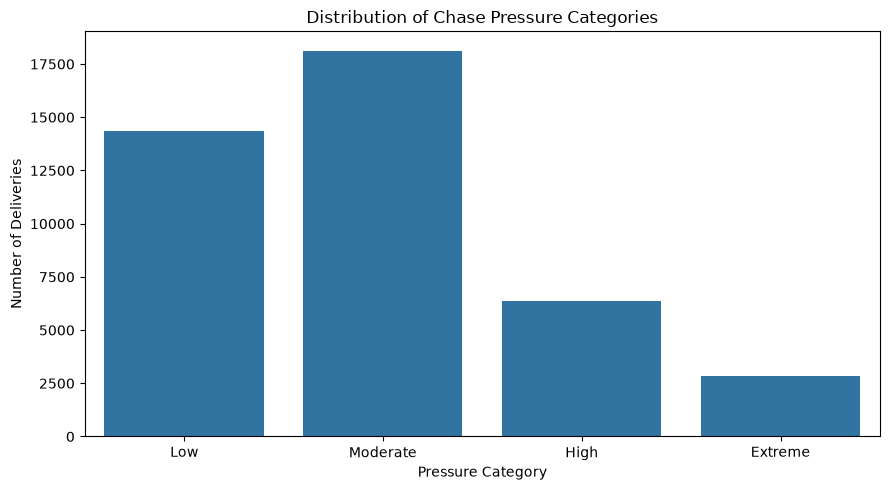

In [50]:
pressure_counts = (
    viable_chase["pressure_category"]
    .value_counts()
    .reindex(["Low", "Moderate", "High", "Extreme"])
)

plt.figure(figsize=(9, 5))

sns.barplot(
    x=pressure_counts.index,
    y=pressure_counts.values
)

plt.title("Distribution of Chase Pressure Categories")
plt.xlabel("Pressure Category")
plt.ylabel("Number of Deliveries")
plt.tight_layout()
plt.show()

In [51]:
pressure_validation = (
    viable_chase
    .groupby("pressure_category", observed=False)
    .agg(
        delivery_count=("combined_pressure_score", "count"),
        avg_required_run_rate=("required_run_rate", "mean"),
        avg_wickets_remaining=("wickets_remaining", "mean"),
        avg_balls_remaining=("legal_balls_remaining", "mean"),
        avg_pressure_score=("combined_pressure_score", "mean")
        )
    .round(2)
)

print(pressure_validation)

                   delivery_count  avg_required_run_rate  \
pressure_category                                          
Low                         14364                   8.75   
Moderate                    18130                   9.49   
High                         6362                  13.73   
Extreme                      2844                  38.15   

                   avg_wickets_remaining  avg_balls_remaining  \
pressure_category                                               
Low                                 9.38                97.28   
Moderate                            7.36                55.71   
High                                4.92                29.50   
Extreme                             2.99                12.51   

                   avg_pressure_score  
pressure_category                      
Low                             16.30  
Moderate                        36.21  
High                            59.86  
Extreme                         84.96  


In [52]:
pressure_output = viable_chase.copy()

pressure_output.to_csv(
    OUTPUT_PATH + "ipl_chase_pressure_deliveries.csv",
    index=False
)

print("Pressure dataset saved successfully.")
print("Rows:", pressure_output.shape[0])
print("Columns:", pressure_output.shape[1])

Pressure dataset saved successfully.
Rows: 41700
Columns: 51
